# Custom Convolutional Neural Network for Plant Disease Classification
## Image preprocessing, feature extraction and a CNN trained from scratch

*COMP6001 - Computer Vision and Multimodal Machine Learning - Final Project*

## Section 1 - Objective of this Notebook

This notebook designs, trains and analyses the **main model** of the project: a **custom convolutional neural network (CNN) built and trained from scratch**, with no pretrained weights. It also covers the steps that come before the model, namely preparing the images and extracting features from them.

The notebook does the following:

1. explains why a CNN is chosen, and what its strengths and weaknesses are (Sections 2 - 3);
2. preprocesses the images and shows the effect of every step (Section 6);
3. extracts hand-crafted features (colour histograms and HOG), which the classical benchmark models will use later (Section 7);
4. defines the CNN architecture and analyses its size and computational cost (Sections 8 - 9);
5. trains and evaluates the network (Sections 10 - 12);
6. looks at what the network has learned and compares learned features with hand-crafted ones (Section 13);
7. summarises the pros and cons of the method using measured evidence (Section 14).

The notebook needs `data/splits.csv`, which is created by the dataset analysis notebook, so run that one first.

## Section 2 - Why a Custom CNN? Reasons for Choosing the Method

**1. The problem is about local visual patterns.** A leaf disease shows up as spots, rings, mould, discolouration or curling in a particular region of the leaf. A convolution looks at a small neighbourhood of pixels and reacts to such a pattern wherever it occurs, which is exactly what is needed.

**2. No manual feature design.** Classical pipelines first compute features by hand (colour histograms, HOG, texture descriptors) and then classify them. The quality of the result depends on how well those features were chosen, and they must be redesigned for each new problem. A CNN learns its features directly from the pixels, from edges and colours in the first layers up to lesion shapes in the last.

**3. Weight sharing keeps the model small.** The same filter is applied at every position, so a conv layer has far fewer parameters than a fully connected layer on the same image. A small network suits roughly 23,000 training images and can later run on a phone.

**4. Fits the dataset.** The images all have the same size and are centred leaves on a plain background, which is a good fit for a shallow CNN of four convolutional blocks.

**5. Comparable with previous work.** Mohanty et al. (2016) used AlexNet and GoogLeNet on the same dataset. Our network follows the same stacked convolution-pooling design (LeNet / AlexNet pattern) in a smaller form.

**6. Training from scratch is a deliberate choice.** Building our own network lets us control and explain every layer. The benchmark notebook later compares it against a pretrained network (ResNet18) to measure what transfer learning adds.

**What makes it "custom".** The architecture (number of blocks, filter counts, normalisation, pooling, classifier head), the preprocessing pipeline, the augmentation and the training procedure are all designed and tuned in this project rather than taken from a library model.

## Section 3 - Pros and Cons of the Selected Method

The table lists the general strengths and weaknesses of this kind of model. Section 14 returns to these points with the numbers measured in this notebook.

| Pros | Cons |
|---|---|
| Learns features automatically, so no feature engineering is needed | Needs many labelled images and much more computation than a classical model |
| Weight sharing gives a small model that is fast at prediction time | A shallow network has less capacity than deep or pretrained networks such as ResNet |
| Convolution and pooling make it tolerant to small shifts of the lesion | A black box: it is hard to explain why an image got a certain label |
| Augmentation, dropout and batch normalisation give strong control over overfitting | Many hyper-parameters (filters, learning rate, dropout) must be tuned |
| Trained from scratch, so it does not depend on ImageNet features | Can learn dataset shortcuts such as the plain background, so accuracy on real field photographs is likely to be much lower |

## Section 4 - Theory of the Building Blocks

**Convolution.** A convolutional layer slides a small filter $K$ (here $3\times 3$) over the input and computes a weighted sum at each position:

$$
(I * K)(i,j) = \sum_{m}\sum_{n} I(i+m,\,j+n)\,K(m,n) + b .
$$

With input size $H$, kernel size $k$, padding $P$ and stride $S$ the output size is

$$
H_{\text{out}} = \left\lfloor \frac{H + 2P - k}{S} \right\rfloor + 1,
$$

and a layer with $C_{\text{in}}$ input and $C_{\text{out}}$ output channels has $k^{2}\,C_{\text{in}}\,C_{\text{out}}$ weights (plus $C_{\text{out}}$ biases). Using $k=3$, $P=1$, $S=1$ keeps the size unchanged.

**Batch normalisation** standardises each channel over a mini-batch $\mathcal{B}$ and then rescales it with learned parameters $\gamma,\beta$, which makes training from scratch faster and more stable:

$$
\hat{x} = \frac{x-\mu_{\mathcal{B}}}{\sqrt{\sigma_{\mathcal{B}}^{2}+\epsilon}}, \qquad y = \gamma\,\hat{x} + \beta .
$$

**ReLU and max pooling.** $\text{ReLU}(x)=\max(0,x)$ adds non-linearity. A $2\times 2$ max-pool keeps the largest value in each window, halving the height and width.

**Dropout** randomly sets each hidden unit to zero with probability $p$ during training (and rescales the rest by $1/(1-p)$), which reduces overfitting.

**Softmax and cross-entropy.** The final layer gives one score (logit) $z_c$ per class. Softmax turns the scores into probabilities and cross-entropy measures how far they are from the true class $y$:

$$
p_c = \frac{e^{z_c}}{\sum_{j=1}^{K} e^{z_j}}, \qquad
\mathcal{L} = -\sum_{c=1}^{K} y_c \log p_c .
$$

If class weights are used (Section 10), each sample's loss is multiplied by $w_c = \dfrac{N}{K\,n_c}$, so small classes count more.

**Adam optimiser.** With gradient $g_t$ of the loss, learning rate $\eta$ and constants $\beta_1,\beta_2,\epsilon$,

$$
m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t,\qquad v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^{2},\qquad
\theta_t=\theta_{t-1}-\eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon},
$$

where $\hat m_t, \hat v_t$ are bias-corrected averages. A weight-decay term $\lambda\lVert\theta\rVert^2$ is added to the loss as an L2 penalty.

## Section 5 - Install and Import Libraries, Configuration

The install cell uses IPython's `%pip` so `scikit-image` is installed into the active notebook kernel (the same environment used by the imports below). It is safe to run again if the package is already installed.

In [3]:
%pip install scikit-image

  Using cached imageio-2.38.1-py3-none-any.whl.metadata (9.7 kB)
  Using cached lazy_loader-0.6-py3-none-any.whl.metadata (6.0 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 2.8 MB/s eta 0:00:00a 0:00:01
Using cached imageio-2.38.1-py3-none-any.whl (328 kB)
Using cached lazy_loader-0.6-py3-none-any.whl (8.8 kB)

[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip3.11 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import warnings
warnings.filterwarnings("ignore")

import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

from skimage.feature import hog
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, silhouette_score)

**Configuration.** All the settings that can be changed live in one cell.

* `QUICK_TEST = True` trains on a tiny subset for two epochs, just to check that the notebook runs (about two minutes). Set it to `False` for the real run.
* `IMG_SIZE = 256` follows the proposal; the pooling layer makes the network work for other sizes too. Using 128 makes training about four times faster.
* `USE_CLASS_WEIGHTS` switches on the weighted loss from Section 4 to compensate for class imbalance.
* `NUM_WORKERS = 0` is the safe choice inside notebooks (especially on macOS).

A full run (30 epochs, 256 x 256) takes roughly one to two hours on a laptop, so try the quick test first.

In [5]:
QUICK_TEST = False
IMG_SIZE = 256
BATCH_SIZE = 32
EPOCHS = 30
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.5
PATIENCE = 7                 # early stopping: stop if validation macro-F1 does not improve for 7 epochs
USE_CLASS_WEIGHTS = False
NUM_WORKERS = 0
SEED = 42

LIMIT = 150 if QUICK_TEST else None
if QUICK_TEST:
    EPOCHS = 2

RUN_NAME = "custom_cnn" + ("_weighted" if USE_CLASS_WEIGHTS else "")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", DEVICE, "| run:", RUN_NAME)

PyTorch: 2.14.0 | device: mps | run: custom_cnn


Folders: data is read from `data/`, the trained network goes to `models/`, and figures and tables go to `results/custom_cnn/`. Predictions are stored separately in `results/predictions/` so that the comparison notebook can read them later. The plotting style is kept plain.

In [6]:
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT_DIR / "data"
MODELS = ROOT_DIR / "models"
RESULTS = ROOT_DIR / "results" / "custom_cnn"
PRED_DIR = ROOT_DIR / "results" / "predictions"
for d in (MODELS, RESULTS, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def save_show(name):
    plt.tight_layout()
    plt.savefig(RESULTS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

**Load the split.** The file `data/splits.csv` (from the dataset notebook) lists every image with its class and its split (train / val / test). Using the same file for every model guarantees that all models are trained and tested on identical images. In quick-test mode a small random subset of each split is used.

In [7]:
splits_file = DATA_DIR / "splits.csv"
assert splits_file.exists(), "data/splits.csv not found - run the dataset analysis notebook first."

df = pd.read_csv(splits_file)
df["path"] = df["path"].map(lambda p: str(ROOT_DIR / p))
class_names = df.drop_duplicates("label").sort_values("label")["class_name"].tolist()
NUM_CLASSES = len(class_names)

frames = {}
for s in ["train", "val", "test"]:
    f = df[df["split"] == s]
    frames[s] = f.sample(min(len(f), LIMIT), random_state=SEED) if LIMIT else f

print({s: len(f) for s, f in frames.items()}, "| classes:", NUM_CLASSES)

{'train': 18786, 'val': 2348, 'test': 2349} | classes: 17


## Section 6 - Image Preprocessing

A network needs inputs of one fixed size and with sensible numerical ranges. The preprocessing pipeline has three steps.

1. **Resize** every image to $256\times256$ pixels. (The PlantVillage images already have this size, so the step mainly guards against odd files.)
2. **Scale** pixel values from $\{0,\dots,255\}$ to $[0,1]$.
3. **Normalise** each colour channel $k$ with a mean $\mu_k$ and standard deviation $\sigma_k$:

$$
x'_k = \frac{x_k-\mu_k}{\sigma_k}.
$$

This centres the data around 0 with unit spread, so that gradients behave well and no channel dominates. We use the ImageNet statistics $\mu=(0.485,0.456,0.406)$ and $\sigma=(0.229,0.224,0.225)$ for **all** models in the project; this is required for the pretrained ResNet18 benchmark and keeps every model on identical inputs. The next cell checks how far these values are from the real statistics of our training images.

In [8]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

# measure the real channel mean / std on a random sample of training images
sub = frames["train"].sample(min(400, len(frames["train"])), random_state=SEED)
pix = np.concatenate([np.asarray(Image.open(p).convert("RGB").resize((64, 64)), dtype=np.float32).reshape(-1, 3) / 255
                      for p in sub["path"]])
stat = pd.DataFrame({"channel": list("RGB"), "dataset mean": pix.mean(0).round(3), "ImageNet mean": MEAN,
                     "dataset std": pix.std(0).round(3), "ImageNet std": STD})
display(stat)

,channel,dataset mean,ImageNet mean,dataset std,ImageNet std
0,R,0.448,0.485,0.180,0.229
1,G,0.463,0.456,0.157,0.224
2,B,0.406,0.406,0.195,0.225


The values are close enough that ImageNet statistics work well here. The figure shows what normalisation does to the pixel distribution of one channel: the histogram keeps its shape but moves to be centred near zero.

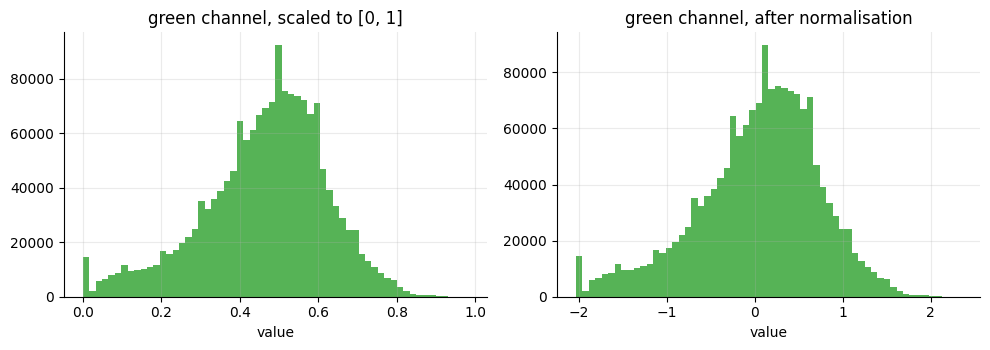

In [9]:
x = pix[:, 1]                                  # green channel
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(x, bins=60, color="tab:green", alpha=0.8)
ax[0].set_title("green channel, scaled to [0, 1]"); ax[0].set_xlabel("value")
ax[1].hist((x - MEAN[1]) / STD[1], bins=60, color="tab:green", alpha=0.8)
ax[1].set_title("green channel, after normalisation"); ax[1].set_xlabel("value")
save_show("normalisation_effect")

**Data augmentation** creates new training images by randomly changing existing ones, so the network cannot simply memorise them. It is applied to the **training images only**; validation and test images are never altered. The random changes used are:

* **rotation** by an angle $\theta \sim U(-20^\circ, 20^\circ)$, because leaves are photographed at any orientation;
* **horizontal flip** with probability $0.5$, since a mirrored leaf is still a valid leaf;
* **random resized crop**: a region covering a random fraction $s\sim U(0.7, 1)$ of the image is cut out and resized back to $256\times256$, which teaches the network to recognise lesions at different scales and positions.

The cell below defines both pipelines and shows one leaf together with five random augmentations of it.

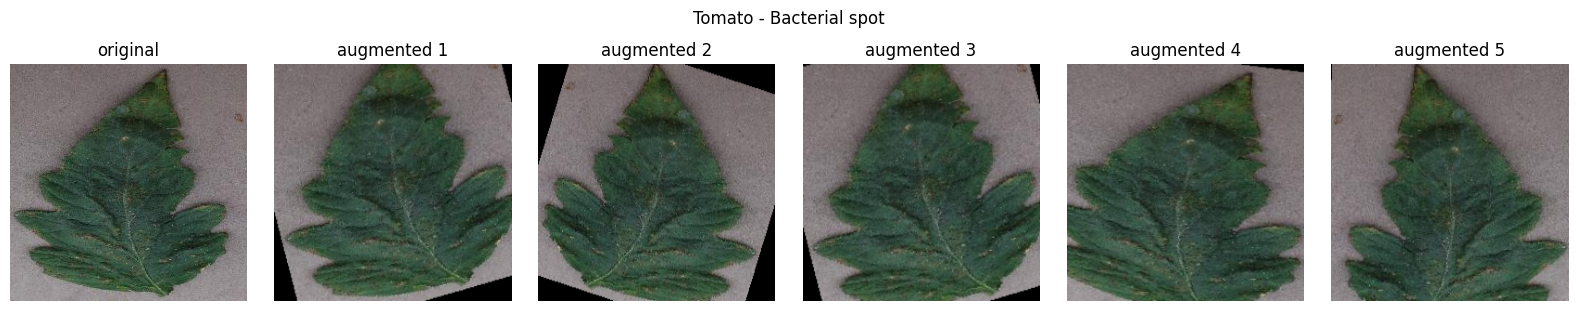

In [10]:
train_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomRotation(20),
    T.RandomHorizontalFlip(),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

# undo the normalisation only for display
unnorm = T.Normalize([-m / s for m, s in zip(MEAN, STD)], [1 / s for s in STD])

row = frames["train"].sample(1, random_state=5).iloc[0]
img = Image.open(row["path"]).convert("RGB")
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(img); axes[0].set_title("original")
for k in range(1, 6):
    axes[k].imshow(unnorm(train_tf(img)).permute(1, 2, 0).clamp(0, 1)); axes[k].set_title(f"augmented {k}")
for a in axes:
    a.axis("off")
fig.suptitle(row["class_name"], y=1.02)
save_show("augmentation_examples")

## Section 7 - Hand-Crafted Feature Extraction

Before the CNN, two classical feature types are extracted. They show what "meaningful features" look like when designed by hand, and they are the inputs of the SVM and random forest benchmarks in the next notebook.

**Colour histogram.** For each channel the pixels are counted in $B$ equal intensity bins and divided by the number of pixels. With $B=16$ and three channels this gives a $48$-dimensional vector that describes the overall colour of the leaf and its lesions, but nothing about their shape.

**Histogram of Oriented Gradients (HOG).** HOG describes local shape and texture through edge directions. On the grayscale image the gradients are

$$
G_x = I(x+1,y)-I(x-1,y),\qquad G_y = I(x,y+1)-I(x,y-1),
$$

with magnitude $m=\sqrt{G_x^{2}+G_y^{2}}$ and orientation $\theta=\operatorname{atan2}(G_y,G_x)$ (taken modulo $180^\circ$). The image is divided into $16\times16$ pixel cells; in each cell the magnitudes are summed into a histogram of 9 orientation bins. Blocks of $2\times2$ cells are then normalised, $v \leftarrow v/\sqrt{\lVert v\rVert^{2}+\varepsilon^{2}}$, to make the descriptor robust to lighting changes. For a $256\times256$ image this gives $15\times15$ blocks $\times\,(2\cdot2\cdot9)=8100$ values.

The next cell defines both extractors, computes them for one image from each of three classes, and displays the original image, the colour histogram and the HOG picture, where bright strokes mark strong edges in the stroke's direction.

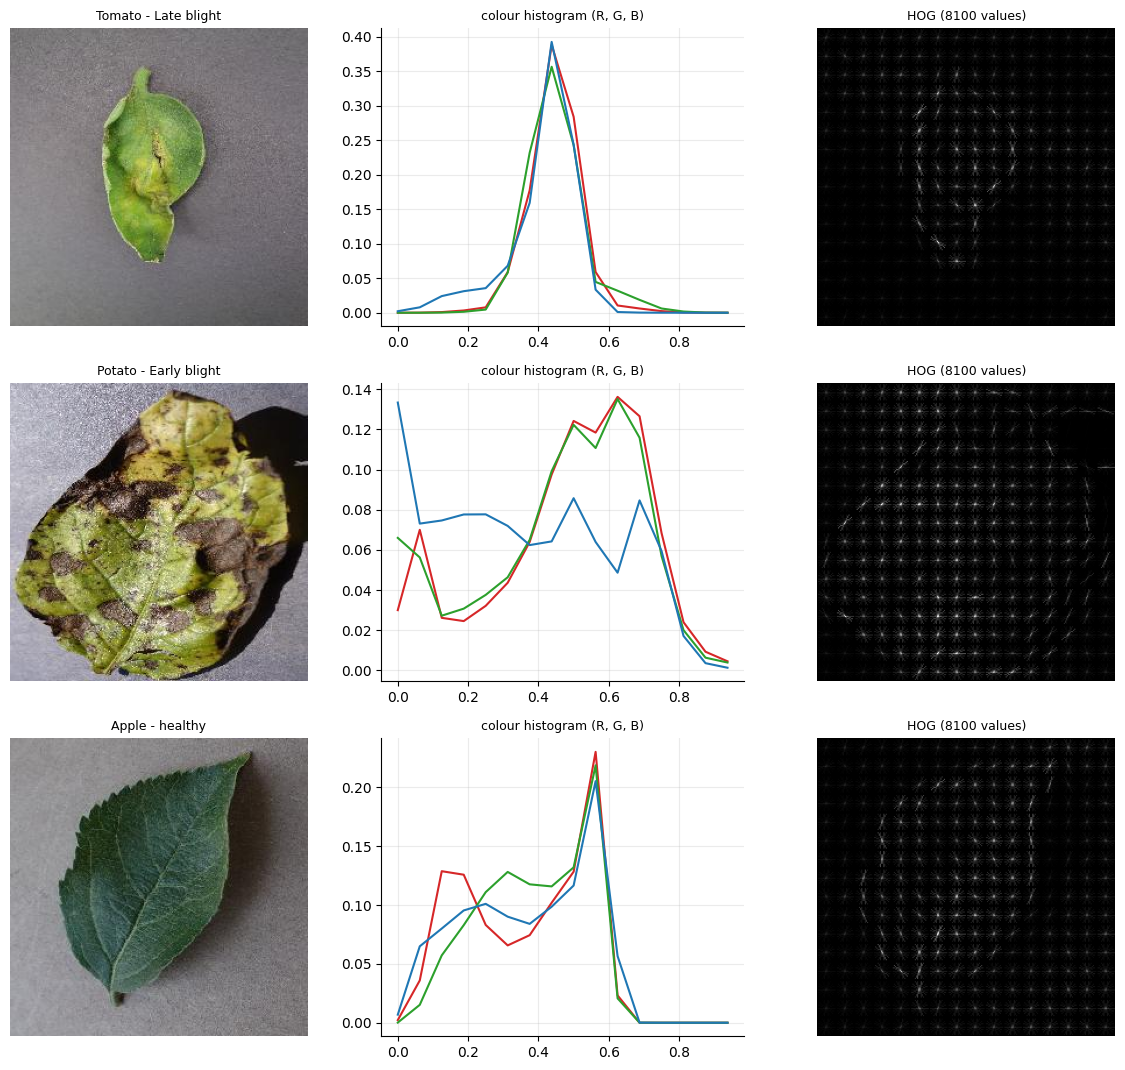

In [11]:
BINS = 16

def colour_hist(pil_img, bins=BINS):
    a = np.asarray(pil_img.convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32) / 255
    return np.concatenate([np.histogram(a[..., k], bins=bins, range=(0, 1))[0] for k in range(3)]) / a[..., 0].size

def hog_feat(pil_img, visualize=False):
    gray = np.asarray(pil_img.convert("L").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32) / 255
    return hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2),
               block_norm="L2-Hys", visualize=visualize)

demo = [c for c in ["Tomato - Late blight", "Potato - Early blight", "Apple - healthy"] if c in class_names] or class_names[:3]
fig, axes = plt.subplots(len(demo), 3, figsize=(12, 3.6 * len(demo)))
axes = np.atleast_2d(axes)
for r, c in enumerate(demo):
    p = df[df["class_name"] == c].sample(1, random_state=2)["path"].iloc[0]
    im = Image.open(p).convert("RGB")
    h, hog_img = hog_feat(im, visualize=True)
    ch = colour_hist(im)
    axes[r, 0].imshow(im); axes[r, 0].axis("off"); axes[r, 0].set_title(c, fontsize=9)
    for k, col in enumerate(["tab:red", "tab:green", "tab:blue"]):
        axes[r, 1].plot(np.arange(BINS) / BINS, ch[k * BINS:(k + 1) * BINS], color=col)
    axes[r, 1].set_title("colour histogram (R, G, B)", fontsize=9)
    axes[r, 2].imshow(hog_img, cmap="gray"); axes[r, 2].axis("off"); axes[r, 2].set_title(f"HOG ({len(h)} values)", fontsize=9)
save_show("handcrafted_features")

These features are fixed by us in advance. The CNN below instead *learns* its own features during training, and Section 13 compares the two.

## Section 8 - Data Loading and Model Architecture

**Data loaders.** A `Dataset` returns one preprocessed image and its label; a `DataLoader` groups them into mini-batches of 32. Only the training loader shuffles. The class weights $w_c=N/(K n_c)$ from Section 4 are computed from the training split.

In [12]:
class PlantDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame["path"].tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.transform(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

loaders = {s: DataLoader(PlantDataset(frames[s], train_tf if s == "train" else eval_tf),
                         batch_size=BATCH_SIZE, shuffle=(s == "train"), num_workers=NUM_WORKERS)
           for s in frames}

n_c = np.bincount(frames["train"]["label"], minlength=NUM_CLASSES).astype(float)
class_weights = torch.tensor(n_c.sum() / (NUM_CLASSES * np.maximum(n_c, 1)), dtype=torch.float32)
print("Batches per epoch (train):", len(loaders["train"]))

Batches per epoch (train): 588


**Architecture.** The network has two parts.

*Feature extractor:* four identical blocks of `Conv 3x3 -> BatchNorm -> ReLU -> MaxPool 2x2` with 32, 64, 128 and 256 filters. Each block doubles the number of channels and halves the image size, so the network looks for simple patterns first and combines them into more complex ones: $256\to128\to64\to32\to16$ pixels.

*Classifier:* an adaptive $4\times4$ average pool, flattening to $256\cdot16=4096$ values, a fully connected layer with 256 units and ReLU, dropout ($p=0.5$), and a final fully connected layer with one output per class. Softmax is applied inside the loss function.

Two design decisions differ from the plain proposal and are part of what makes the model custom. **Batch normalisation** was added to make training from scratch stable. The **adaptive average pool** reduces the feature map to $4\times4$ before the fully connected layer; without it that layer would need $256\cdot16\cdot16\cdot256\approx16.8$ million weights, with it only about $1$ million, which lowers the risk of overfitting.

In [13]:
class ConvBlock(nn.Module):
    """Conv 3x3 -> BatchNorm -> ReLU -> MaxPool 2x2 (halves height and width)."""
    def __init__(self, c_in, c_out):
        super().__init__()
        self.conv = nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False)   # bias is redundant before BatchNorm
        self.bn = nn.BatchNorm2d(c_out)
        self.pool = nn.MaxPool2d(2)
    def forward(self, x):
        return self.pool(torch.relu(self.bn(self.conv(x))))


class PlantCNN(nn.Module):
    def __init__(self, num_classes, channels=(32, 64, 128, 256), hidden=256, dropout=0.5):
        super().__init__()
        blocks, c_in = [], 3
        for c in channels:
            blocks.append(ConvBlock(c_in, c))
            c_in = c
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.fc1 = nn.Linear(c_in * 4 * 4, hidden)
        self.drop = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden, num_classes)

    def embed(self, x):
        """256-dimensional learned feature vector (used for analysis in Section 13)."""
        x = torch.flatten(self.pool(self.features(x)), 1)
        return torch.relu(self.fc1(x))

    def forward(self, x):
        return self.fc2(self.drop(self.embed(x)))          # raw logits


model = PlantCNN(NUM_CLASSES, dropout=DROPOUT).to(DEVICE)
print(model)

PlantCNN(
  (features): Sequential(
    (0): ConvBlock(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): ConvBlock(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): ConvBlock(
      (conv): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): ConvBlock(
      (conv):

**Check the shapes.** A dummy image is passed through the network one stage at a time. The printed sizes should follow the formula $H_{\text{out}}=\lfloor (H+2P-k)/S\rfloor+1$ and the halving by pooling.

In [14]:
x = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
model.eval()
with torch.no_grad():
    print(f"input            {tuple(x.shape)}")
    for i, blk in enumerate(model.features, 1):
        x = blk(x)
        print(f"after block {i}    {tuple(x.shape)}")
    x = model.pool(x)
    print(f"after avg-pool   {tuple(x.shape)}")
    print(f"output (logits)  {tuple(model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)).shape)}")

input            (1, 3, 256, 256)
after block 1    (1, 32, 128, 128)
after block 2    (1, 64, 64, 64)
after block 3    (1, 128, 32, 32)
after block 4    (1, 256, 16, 16)
after avg-pool   (1, 256, 4, 4)
output (logits)  (1, 17)


## Section 9 - Computational and Memory Complexity

The cost of the network can be worked out exactly from the layer sizes.

**Parameters.** A conv layer without bias has $k^{2}C_{\text{in}}C_{\text{out}}$ weights, batch norm adds $2C_{\text{out}}$ (the $\gamma$ and $\beta$ values), and a fully connected layer has $n_{\text{in}}n_{\text{out}}+n_{\text{out}}$.

**Computation.** Counting one multiply-accumulate (MAC) as one operation, a convolution costs

$$
\text{MACs}_{\text{conv}} = H_{\text{out}}\,W_{\text{out}}\,C_{\text{out}}\,(k^{2}C_{\text{in}}),
\qquad
\text{MACs}_{\text{fc}} = n_{\text{in}}\,n_{\text{out}} .
$$

**Memory.** Weights need $4$ bytes per parameter (float32); the activations of one image need $4$ bytes per value of every layer output. Training roughly triples the compute (forward plus backward pass) and the activation memory grows linearly with the batch size.

The cell measures each layer with forward hooks and adds up the totals, and then checks the first conv layer against the formula.

In [15]:
rows = []
def make_hook(name):
    def hook(m, inp, out):
        if isinstance(m, nn.Conv2d):
            macs = out.shape[2] * out.shape[3] * m.out_channels * (m.in_channels * m.kernel_size[0] * m.kernel_size[1])
        elif isinstance(m, nn.Linear):
            macs = m.in_features * m.out_features
        else:
            macs = 0
        rows.append(dict(layer=name, type=type(m).__name__, output_shape=tuple(out.shape[1:]),
                         params=sum(p.numel() for p in m.parameters(recurse=False)),
                         MACs=macs, activation_MB=round(out.numel() * 4 / 1e6, 2)))
    return hook

hooks = [m.register_forward_hook(make_hook(n)) for n, m in model.named_modules()
         if isinstance(m, (nn.Conv2d, nn.BatchNorm2d, nn.MaxPool2d, nn.AdaptiveAvgPool2d, nn.Linear))]
model.eval()
with torch.no_grad():
    model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))
for h in hooks:
    h.remove()

cx = pd.DataFrame(rows)
display(cx)

n_params = sum(p.numel() for p in model.parameters())
total_macs = cx["MACs"].sum()
print(f"Parameters       : {n_params:,}  ({n_params * 4 / 1e6:.1f} MB as float32)")
print(f"Compute          : {total_macs / 1e6:,.0f} million MACs per image (forward pass)")
print(f"Activation memory: {cx['activation_MB'].sum():.1f} MB per image")
print(f"Check, first conv: formula 3*3*3*32 = {3*3*3*32}, measured {cx.iloc[0]['params']}")

,layer,type,output_shape,params,MACs,activation_MB
0,features.0.conv,Conv2d,"(32, 256, 256)",864,56623104,8.39
1,features.0.bn,BatchNorm2d,"(32, 256, 256)",64,0,8.39
2,features.0.pool,MaxPool2d,"(32, 128, 128)",0,0,2.10
3,features.1.conv,Conv2d,"(64, 128, 128)",18432,301989888,4.19
4,features.1.bn,BatchNorm2d,"(64, 128, 128)",128,0,4.19
5,features.1.pool,MaxPool2d,"(64, 64, 64)",0,0,1.05
6,features.2.conv,Conv2d,"(128, 64, 64)",73728,301989888,2.10
7,features.2.bn,BatchNorm2d,"(128, 64, 64)",256,0,2.10
8,features.2.pool,MaxPool2d,"(128, 32, 32)",0,0,0.52
9,features.3.conv,Conv2d,"(256, 32, 32)",294912,301989888,1.05


Parameters       : 1,442,097  (5.8 MB as float32)
Compute          : 964 million MACs per image (forward pass)
Activation memory: 35.4 MB per image
Check, first conv: formula 3*3*3*32 = 864, measured 864


**Reading the table.** The compute is dominated by the early convolutions, which work on large images, even though they have few weights. The parameters are concentrated in the last conv block and the fully connected layer. This is the usual trade-off of CNNs: early layers are expensive in time, late layers are expensive in memory for weights.

## Section 10 - Loss Function, Optimiser and Training Procedure

The network is trained by minimising the cross-entropy loss from Section 4 with the Adam optimiser and L2 weight decay. In every epoch the training data is passed through the network in mini-batches (forward pass, loss, backward pass, parameter update), and then the validation data is evaluated without updating anything.

Accuracy alone can hide poor performance on small classes, so we also track the **macro-F1 score** on the validation set: the F1 of each class is computed separately and then averaged, so every class counts equally,

$$
\text{F1}_c = \frac{2\,P_c R_c}{P_c+R_c},\qquad \text{F1}_{\text{macro}}=\frac{1}{K}\sum_{c=1}^{K}\text{F1}_c .
$$

**Early stopping and model selection.** The weights from the epoch with the best validation macro-F1 are kept. If this value does not improve for `PATIENCE` epochs, training stops, which prevents the network from overfitting the training images.

In [16]:
loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE) if USE_CLASS_WEIGHTS else None)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

def run_epoch(loader, train):
    model.train(train)
    total, preds, targets = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in tqdm(loader, leave=False, desc="train" if train else "eval"):
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = loss_fn(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * x.size(0)
            preds += out.argmax(1).cpu().tolist()
            targets += y.cpu().tolist()
    p, t = np.array(preds), np.array(targets)
    return total / len(t), float((p == t).mean()), f1_score(t, p, average="macro", zero_division=0)

## Section 11 - Training

The next cell trains the network. After each epoch it prints the training loss and accuracy and the validation loss, accuracy and macro-F1, and saves the weights whenever the validation macro-F1 reaches a new best. The best weights are stored in `models/`.

In [18]:
keys = ["train_loss", "train_acc", "train_f1", "val_loss", "val_acc", "val_f1"]
hist = {k: [] for k in keys}
best_f1, best_state, bad = -1.0, None, 0
t0 = time.time()

for ep in range(1, EPOCHS + 1):
    tr = run_epoch(loaders["train"], True)
    va = run_epoch(loaders["val"], False)
    for k, v in zip(keys, tr + va):
        hist[k].append(v)
    print(f"Epoch {ep:02d}/{EPOCHS} | train loss {tr[0]:.4f} acc {tr[1]:.4f} | "
          f"val loss {va[0]:.4f} acc {va[1]:.4f} macro-F1 {va[2]:.4f}")
    if va[2] > best_f1:
        best_f1, bad = va[2], 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save({"model": best_state, "class_names": class_names, "epoch": ep,
                    "img_size": IMG_SIZE}, MODELS / f"{RUN_NAME}_best.pt")
    else:
        bad += 1
        if bad >= PATIENCE:
            print(f"Early stopping at epoch {ep}")
            break

train_time = time.time() - t0
json.dump({**hist, "train_time_s": train_time}, open(RESULTS / f"{RUN_NAME}_history.json", "w"))
print(f"\nBest validation macro-F1: {best_f1:.4f} | training time: {train_time / 60:.1f} min")

train:   0%|          | 0/588 [00:00<?, ?it/s]

eval:   0%|          | 0/74 [00:00<?, ?it/s]

Epoch 01/30 | train loss 0.8505 acc 0.7283 | val loss 0.6673 acc 0.7913 macro-F1 0.7204


train:   0%|          | 0/588 [00:00<?, ?it/s]

eval:   0%|          | 0/74 [00:00<?, ?it/s]

Epoch 02/30 | train loss 0.7153 acc 0.7665 | val loss 0.6536 acc 0.7939 macro-F1 0.7147


... (80 outputs left out)

Epoch 29/30 | train loss 0.1477 acc 0.9522 | val loss 0.2467 acc 0.9536 macro-F1 0.9423


train:   0%|          | 0/588 [00:00<?, ?it/s]

eval:   0%|          | 0/74 [00:00<?, ?it/s]

Epoch 30/30 | train loss 0.1398 acc 0.9548 | val loss 0.1491 acc 0.9732 macro-F1 0.9683

Best validation macro-F1: 0.9711 | training time: 155.4 min


**Learning curves.** The curves show loss, accuracy and macro-F1 for the training and validation sets. When the validation curve follows the training curve the network generalises well. A growing gap, with training loss falling while validation loss rises, signals overfitting; both curves staying poor signals underfitting.

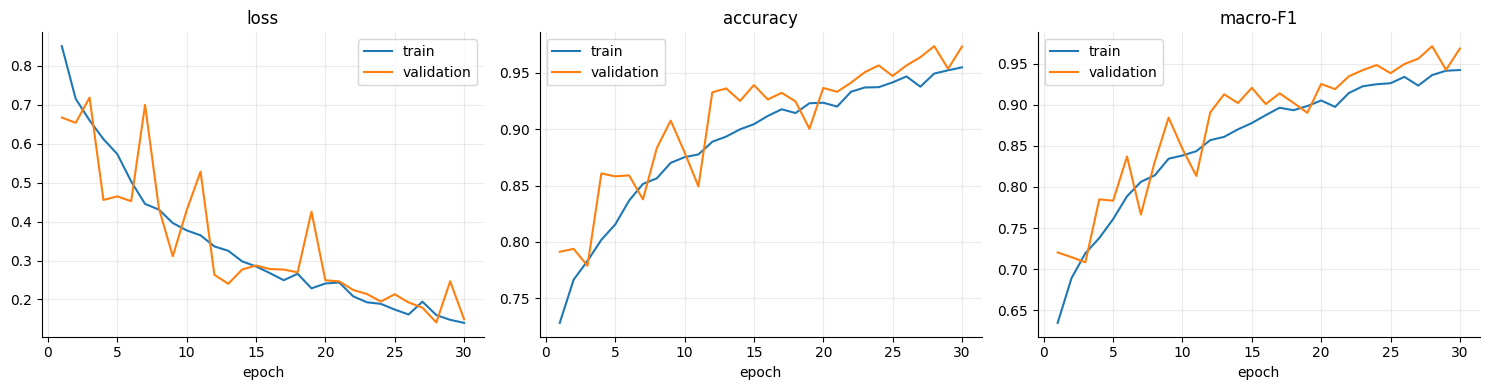

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, k, title in zip(ax, ["loss", "acc", "f1"], ["loss", "accuracy", "macro-F1"]):
    a.plot(range(1, len(hist[f"train_{k}"]) + 1), hist[f"train_{k}"], label="train")
    a.plot(range(1, len(hist[f"val_{k}"]) + 1), hist[f"val_{k}"], label="validation")
    a.set_title(title); a.set_xlabel("epoch"); a.legend()
save_show("learning_curves")

## Section 12 - Evaluation on the Test Set

The test images were not used for training or model selection, so they give an honest estimate of performance on unseen leaves. Besides accuracy we report macro-averaged precision, recall and F1. With true positives, false positives and false negatives $TP_c, FP_c, FN_c$ for class $c$ and $K$ classes,

$$
\text{Precision}_{\text{macro}}=\frac{1}{K}\sum_{c=1}^{K}\frac{TP_c}{TP_c+FP_c},\qquad
\text{Recall}_{\text{macro}}=\frac{1}{K}\sum_{c=1}^{K}\frac{TP_c}{TP_c+FN_c},
$$

and F1 as defined in Section 10. The cell loads the best weights, predicts the whole test set and also measures the prediction time per image. The predictions are saved so that the comparison notebook can test the models against each other.

In [22]:
model.load_state_dict(best_state)
model.to(DEVICE).eval()

preds, targets, conf = [], [], []
t0 = time.time()
with torch.no_grad():
    for x, y in tqdm(loaders["test"], leave=False):
        prob = torch.softmax(model(x.to(DEVICE)), dim=1).cpu()
        preds += prob.argmax(1).tolist()
        conf += prob.max(1).values.tolist()
        targets += y.tolist()
infer_ms = (time.time() - t0) / len(targets) * 1000
y_true, y_pred = np.array(targets), np.array(preds)

acc = accuracy_score(y_true, y_pred)
P, R, F1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
metrics = pd.DataFrame({"metric": ["accuracy", "macro precision", "macro recall", "macro F1"], "score": [acc, P, R, F1]})
display(metrics.round(4))
print(f"Prediction time: {infer_ms:.1f} ms per image (including image loading) on {DEVICE}")

pd.DataFrame({"path": frames["test"]["path"].map(lambda p: str(Path(p).relative_to(ROOT_DIR))).values,
              "y_true": y_true, "y_pred": y_pred, "confidence": conf}).to_csv(PRED_DIR / f"{RUN_NAME}_test_predictions.csv", index=False)
json.dump({"model": RUN_NAME, "accuracy": acc, "macro_precision": P, "macro_recall": R, "macro_f1": F1,
           "parameters": int(n_params), "train_time_s": train_time, "infer_ms_per_image": infer_ms},
          open(PRED_DIR / f"{RUN_NAME}_metrics.json", "w"), indent=1)

  0%|          | 0/74 [00:00<?, ?it/s]

,metric,score
0,accuracy,0.9689
1,macro precision,0.9613
2,macro recall,0.9572
3,macro F1,0.9586


Prediction time: 10.1 ms per image (including image loading) on mps


**Per-class results.** The classification report shows precision, recall and F1 for every class. Classes with few training images or with a similar-looking neighbour are expected to score lowest.

In [23]:
labels = list(range(NUM_CLASSES))
rep = classification_report(y_true, y_pred, labels=labels, target_names=class_names, output_dict=True, zero_division=0)
rep = pd.DataFrame(rep).T.loc[class_names, ["precision", "recall", "f1-score", "support"]]
display(rep.sort_values("f1-score").round(3))

,precision,recall,f1-score,support
Potato - healthy,0.857,0.800,0.828,15.0
Tomato - Target Spot,0.944,0.844,0.891,141.0
Tomato - Early blight,0.896,0.950,0.922,100.0
Potato - Late blight,0.989,0.880,0.931,100.0
Tomato - Late blight,0.957,0.942,0.950,191.0
Tomato - Spider mites,0.923,0.994,0.957,168.0
Tomato - Septoria leaf spot,0.956,0.989,0.972,177.0
Tomato - healthy,0.952,1.000,0.975,159.0
Potato - Early blight,0.952,1.000,0.976,100.0
Apple - Apple scab,0.984,0.968,0.976,63.0


**Confusion matrix.** Entry $(i,j)$ counts test images of true class $i$ predicted as class $j$. The plot is row-normalised, so a cell's colour shows the fraction of class $i$ sent to class $j$; a perfect model would show only the diagonal. Off-diagonal cells reveal which diseases the network mixes up.

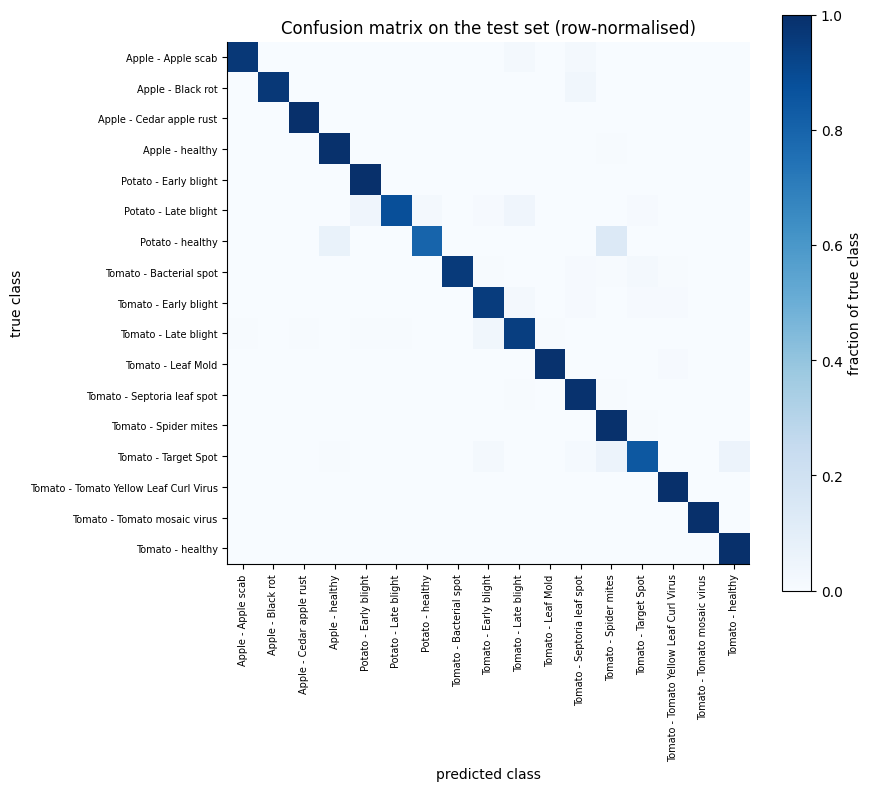

Most frequent confusions (true -> predicted):


,true class,predicted as,images
34,Tomato - Target Spot,Tomato - healthy,8
33,Tomato - Target Spot,Tomato - Spider mites,8
24,Tomato - Late blight,Tomato - Early blight,6
14,Tomato - Bacterial spot,Tomato - Target Spot,4
4,Potato - Late blight,Potato - Early blight,4
7,Potato - Late blight,Tomato - Late blight,4


In [24]:
cm = confusion_matrix(y_true, y_pred, labels=labels)
cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(labels); ax.set_xticklabels(class_names, rotation=90, fontsize=7)
ax.set_yticks(labels); ax.set_yticklabels(class_names, fontsize=7)
ax.grid(False)
ax.set_xlabel("predicted class"); ax.set_ylabel("true class")
ax.set_title("Confusion matrix on the test set (row-normalised)")
fig.colorbar(im, ax=ax, label="fraction of true class")
save_show("confusion_matrix")

off = [(class_names[i], class_names[j], cm[i, j]) for i in labels for j in labels if i != j and cm[i, j] > 0]
print("Most frequent confusions (true -> predicted):")
display(pd.DataFrame(off, columns=["true class", "predicted as", "images"]).sort_values("images", ascending=False).head(6))

## Section 13 - What Has the Network Learned? Learned Features vs Hand-Crafted Features

A CNN is often called a black box, but its learned features can be inspected. Three views are used.

**First-layer filters.** The 32 filters of the first convolution are $3\times3\times3$ colour patches. Plotting them as tiny images shows which simple patterns (edges, colour blobs) the network looks for.

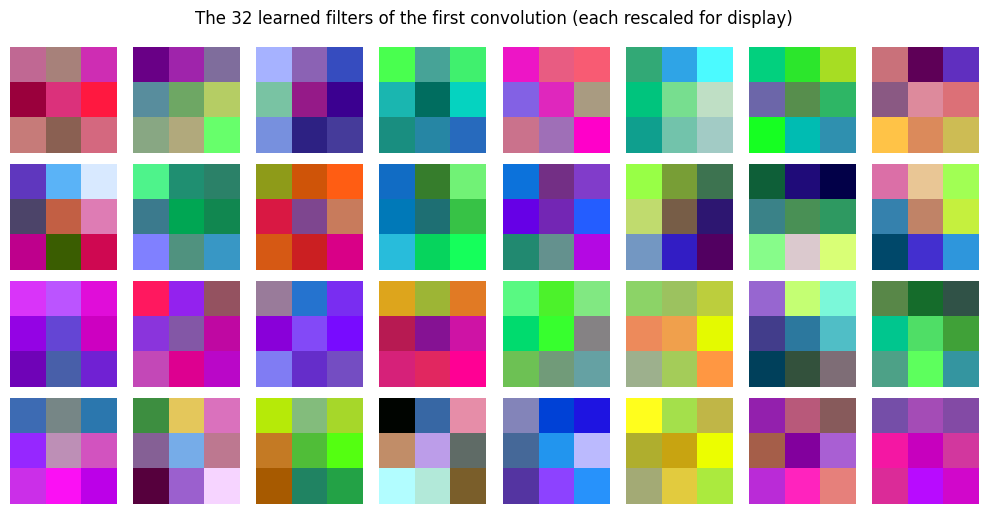

In [25]:
w = model.features[0].conv.weight.detach().cpu().numpy()          # (32, 3, 3, 3)
w = (w - w.min(axis=(1, 2, 3), keepdims=True)) / (np.ptp(w, axis=(1, 2, 3), keepdims=True) + 1e-8)
fig, axes = plt.subplots(4, 8, figsize=(10, 5.2))
for a, f in zip(axes.ravel(), w):
    a.imshow(f.transpose(1, 2, 0), interpolation="nearest"); a.axis("off")
fig.suptitle("The 32 learned filters of the first convolution (each rescaled for display)")
save_show("first_layer_filters")

**Feature maps.** Passing one leaf through the first block gives 32 response maps, one per filter. Bright areas mark where a filter found its pattern. Diseased regions should light up in some maps.

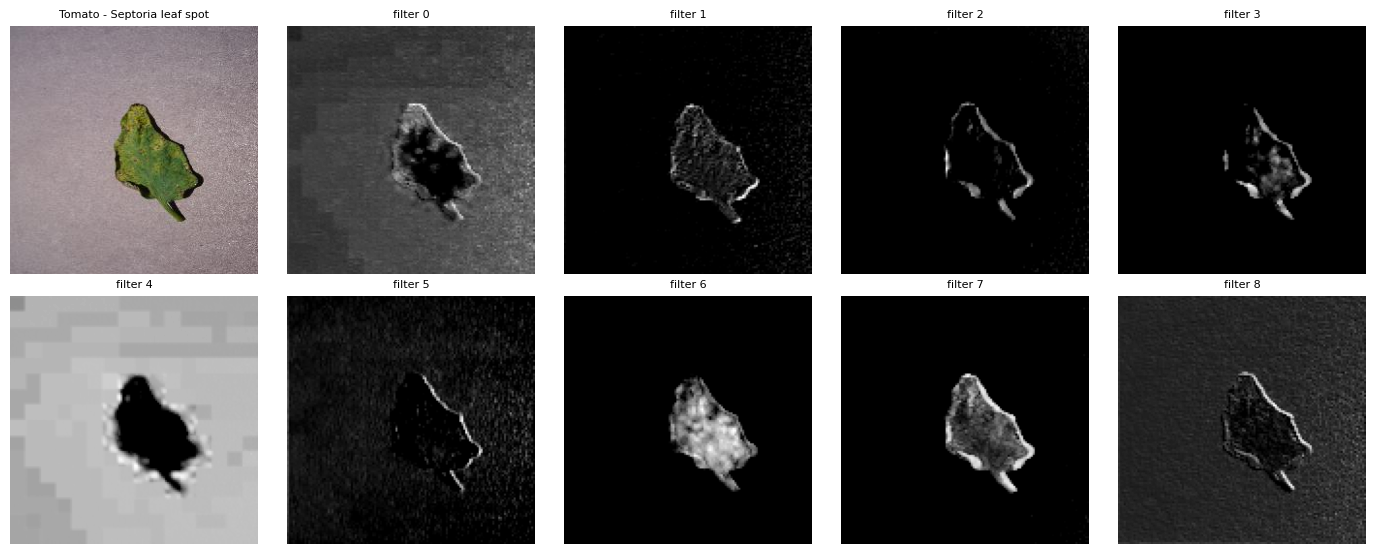

In [26]:
row = frames["test"][frames["test"]["is_healthy"] == False].sample(1, random_state=4).iloc[0] if (frames["test"]["is_healthy"] == False).any() else frames["test"].iloc[0]
im = Image.open(row["path"]).convert("RGB")
xb = eval_tf(im).unsqueeze(0).to(DEVICE)
with torch.no_grad():
    fmap = model.features[0](xb)[0].cpu().numpy()                 # (32, H/2, W/2)

fig, axes = plt.subplots(2, 5, figsize=(14, 5.6))
axes[0, 0].imshow(im); axes[0, 0].set_title(row["class_name"], fontsize=8)
for a in axes.ravel():
    a.axis("off")
for k, a in enumerate(axes.ravel()[1:10]):
    a.imshow(fmap[k], cmap="gray"); a.set_title(f"filter {k}", fontsize=8)
save_show("feature_maps_block1")

**Learned embedding vs hand-crafted features.** The 256-value output of the first fully connected layer is the network's summary of an image. If the learned features are meaningful, images of one class should end up close together. Two tools measure this.

*t-SNE* maps the high-dimensional vectors to two dimensions so that neighbours stay neighbours (it minimises the Kullback-Leibler divergence between neighbour probabilities in the original and in the 2-D space), giving a picture of the feature space.

The *silhouette score* quantifies class separation. For a sample $i$ let $a_i$ be its mean distance to the other samples of its own class and $b_i$ its mean distance to the nearest other class; then

$$
s_i=\frac{b_i-a_i}{\max(a_i,b_i)}\in[-1,1],
$$

and the score is the average over all samples (higher means better separated classes). It is computed for the learned embedding and for the hand-crafted colour histogram of Section 7 on the same test images.

Silhouette score - learned CNN embedding : 0.236
Silhouette score - colour histogram      : -0.123


Python(7158) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


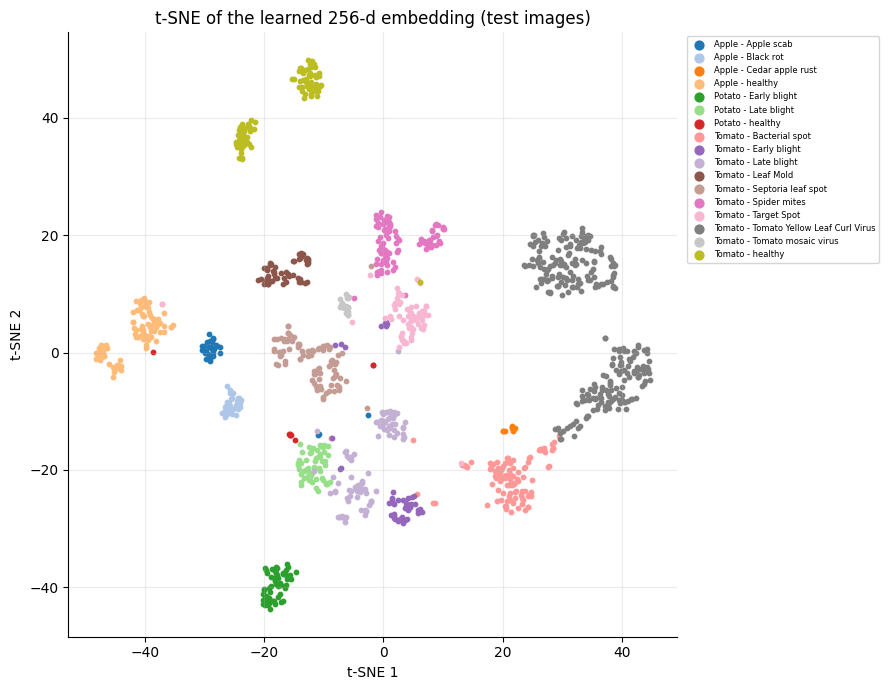

In [27]:
sub = frames["test"].sample(min(1200, len(frames["test"])), random_state=SEED)
emb, colour, lab = [], [], []
model.eval()
with torch.no_grad():
    for p, l in zip(sub["path"], sub["label"]):
        im = Image.open(p).convert("RGB")
        emb.append(model.embed(eval_tf(im).unsqueeze(0).to(DEVICE)).cpu().numpy()[0])
        colour.append(colour_hist(im))
        lab.append(l)
emb, colour, lab = np.array(emb), np.array(colour), np.array(lab)

sil_cnn = silhouette_score(emb, lab)
sil_col = silhouette_score(colour, lab)
print(f"Silhouette score - learned CNN embedding : {sil_cnn:.3f}")
print(f"Silhouette score - colour histogram      : {sil_col:.3f}")

perp = max(5, min(30, (len(emb) - 1) // 3))
z = TSNE(n_components=2, perplexity=perp, init="pca", random_state=SEED).fit_transform(emb)
cmap = plt.get_cmap("tab20")
fig, ax = plt.subplots(figsize=(9, 7))
for c in range(NUM_CLASSES):
    m = lab == c
    if m.any():
        ax.scatter(z[m, 0], z[m, 1], s=10, color=cmap(c % 20), label=class_names[c])
ax.legend(fontsize=6, markerscale=2, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_title("t-SNE of the learned 256-d embedding (test images)")
ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2")
save_show("tsne_learned_embedding")

If the silhouette score of the CNN embedding is clearly higher than that of the colour histogram, the learned features separate the classes much better than colour alone, which is the main argument for learning features instead of designing them. If the two scores are close, colour already carries most of the information. Describe whichever you observe, together with the t-SNE picture (compact, well-separated clusters mean good features).

## Section 14 - Pros and Cons Revisited with Evidence

The table collects the measured properties of the trained network. Each value supports one of the points made in Section 3.

In [28]:
gap = hist["train_acc"][int(np.argmax(hist["val_f1"]))] - hist["val_acc"][int(np.argmax(hist["val_f1"]))]
evidence = pd.DataFrame({
    "measurement": ["parameters", "model size (float32)", "compute per image", "training time", "prediction time per image",
                    "test accuracy", "test macro-F1", "lowest per-class recall", "train - validation accuracy gap (best epoch)"],
    "value": [f"{n_params:,}", f"{n_params * 4 / 1e6:.1f} MB", f"{total_macs / 1e6:,.0f} M MACs", f"{train_time / 60:.1f} min",
              f"{infer_ms:.1f} ms", f"{acc:.4f}", f"{F1:.4f}",
              f"{rep['recall'].min():.3f} ({rep['recall'].idxmin()})", f"{gap:+.4f}"],
    "supports": ["small model (pro)", "easy to deploy (pro)", "cost of the early layers (con)", "training is costly (con)",
                 "fast prediction (pro)", "strong accuracy (pro)", "balance across classes", "weak spots on small / similar classes (con)",
                 "overfitting control (pro) or overfitting (con)"],
})
evidence.to_csv(RESULTS / f"{RUN_NAME}_evidence.csv", index=False)
display(evidence)

,measurement,value,supports
0,parameters,"1,442,097",small model (pro)
1,model size (float32),5.8 MB,easy to deploy (pro)
2,compute per image,964 M MACs,cost of the early layers (con)
3,training time,155.4 min,training is costly (con)
4,prediction time per image,10.1 ms,fast prediction (pro)
5,test accuracy,0.9689,strong accuracy (pro)
6,test macro-F1,0.9586,balance across classes
7,lowest per-class recall,0.800 (Potato - healthy),weak spots on small / similar classes (con)
8,train - validation accuracy gap (best epoch),-0.0243,overfitting control (pro) or overfitting (con)


**Points to discuss in the report.**

* *Pros (check each against the table above):* the network is small (a few megabytes), predicts in milliseconds per image and needs no hand-made features; its test accuracy and macro-F1 show how well it performs, and the silhouette comparison in Section 13 shows whether its learned features separate classes better than colour histograms.
* *Cons (check against your results):* training takes far longer than a classical model (compare with the benchmark notebook); accuracy alone can hide weaker classes, so look at macro-F1 and the lowest per-class recall; look at the confusion matrix to see whether errors concentrate on visually similar diseases.
* *Overfitting:* judge it from the learning curves and the train-validation gap above.
* *Limitations:* PlantVillage has uniform backgrounds, so the network may use background cues and will probably perform much worse on field photographs (Mohanty et al. report about 31 % on such images). Results come from one split and one random seed; several photographs can show the same leaf, so a random split may place near-duplicates in different sets. Running the notebook with `USE_CLASS_WEIGHTS = True` tests whether class weighting helps the small classes.
* *Next:* the benchmark notebook trains an SVM, a random forest and a pretrained ResNet18 on the same split, and the comparison notebook tests whether the differences are statistically significant using the predictions saved here.

## Section 15 - Saved Outputs

Everything produced here is stored on disk for the later notebooks:

* `models/<run>_best.pt` - the trained weights;
* `results/predictions/<run>_test_predictions.csv` and `<run>_metrics.json` - test predictions and summary metrics;
* `results/custom_cnn/` - all figures, the training history and the evidence table.

In [29]:
for folder in (MODELS, PRED_DIR, RESULTS):
    print(folder.relative_to(ROOT_DIR))
    for f in sorted(folder.glob(f"*{RUN_NAME}*")) + sorted(folder.glob("*.png")):
        print("   ", f.name)

models
    custom_cnn_best.pt
results/predictions
    custom_cnn_metrics.json
    custom_cnn_test_predictions.csv
results/custom_cnn
    custom_cnn_evidence.csv
    custom_cnn_history.json
    augmentation_examples.png
    confusion_matrix.png
    feature_maps_block1.png
    first_layer_filters.png
    handcrafted_features.png
    learning_curves.png
    normalisation_effect.png
    tsne_learned_embedding.png
